# 금융데이터분석 Week 03 Lab & Assignment
## 가격 기반 기술적 지표와 투자전략
삼성전자(`005930.KS`)의 **2015년 이후 일별 주가**를 이용합니다.

$$
\boxed{\text{Price}\rightarrow\text{Indicator}\rightarrow\text{Signal}\rightarrow\text{Position}\rightarrow\text{Return}\rightarrow\text{Performance}}
$$

핵심 지표는 **SMA, Momentum, Wilder RSI, Bollinger Bands**입니다.

$$
\boxed{\text{Good Backtest Performance}\neq\text{Evidence of Predictability}}
$$

# Part 1. 학습목표
- 가격에서 simple return과 핵심 기술적 지표를 직접 계산한다.
- Indicator → Signal → Position을 구분하고 `shift(1)`을 이해한다.
- 거래비용을 포함한 Long/Flat 전략을 백테스트한다.
- CAGR, Volatility, Sharpe, MDD, Turnover, Trades, Exposure를 비교한다.
- Train/Test와 circular-shift benchmark를 경험한다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

TICKER="005930.KS"
START_DATE="2015-01-01"
TRADING_DAYS=252
COST=0.0015
DATA_DIR=Path("data"); DATA_DIR.mkdir(exist_ok=True)
CACHE_FILE=DATA_DIR/"FDA_week03_samsung_005930.csv"
print(TICKER,START_DATE,COST)

005930.KS 2015-01-01 0.0015


# Part 2. 데이터
Yahoo Finance `auto_adjust=True` 자료를 사용합니다. 다운로드 성공 시 상대경로 CSV cache를 저장하고 실패하면 기존 cache를 사용합니다.

In [2]:
def load_price_data():
    try:
        x=yf.download(TICKER,start=START_DATE,auto_adjust=True,progress=False)
        if x.empty: raise ValueError("empty data")
        if isinstance(x.columns,pd.MultiIndex): x.columns=x.columns.get_level_values(0)
        x=x.reset_index()
        keep=["Date","Open","High","Low","Close","Volume"]
        x=x[[c for c in keep if c in x.columns]].copy()
        x["Date"]=pd.to_datetime(x["Date"])
        x=x.sort_values("Date").reset_index(drop=True)
        x.to_csv(CACHE_FILE,index=False)
        print("Downloaded from Yahoo Finance")
        return x
    except Exception as exc:
        if not CACHE_FILE.exists(): raise RuntimeError("Download failed and no cache exists") from exc
        print("Using local cache")
        return pd.read_csv(CACHE_FILE,parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)

df=load_price_data()
assert not df.empty and "Close" in df.columns
print(len(df),df["Date"].min().date(),df["Date"].max().date())
df.head()

Downloaded from Yahoo Finance
2880 2015-01-02 2026-10-02


Price,Date,Open,High,Low,Close,Volume
0,2015-01-02,20550.187735,20550.187735,20350.820242,20396.828125,8774950
1,2015-01-05,20488.845778,20488.845778,20136.118642,20442.837891,10139500
2,2015-01-06,20166.787562,20197.459482,19752.716639,19860.068359,15235500
3,2015-01-07,19844.730197,20105.441490,19660.698696,20044.097656,14322750
4,2015-01-08,20534.854147,20534.854147,20090.111227,20151.455078,14477600


# Part 3. Price & Return
$$
R_t=\frac{P_t}{P_{t-1}}-1
$$
이번 실습에서는 simple return을 사용합니다.

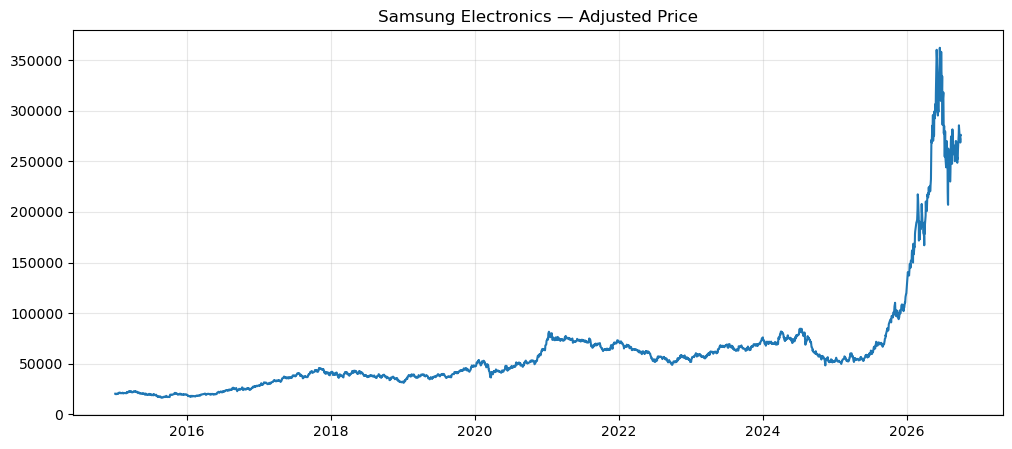

Price,Date,Close,RET
0,2015-01-02,20396.828125,NaN
1,2015-01-05,20442.837891,0.002256
2,2015-01-06,19860.068359,-0.028507
3,2015-01-07,20044.097656,0.009266
4,2015-01-08,20151.455078,0.005356


In [3]:
df["RET"]=df["Close"].pct_change()
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(df["Date"],df["Close"]); ax.set_title("Samsung Electronics — Adjusted Price"); ax.grid(alpha=.3)
plt.show()
df[["Date","Close","RET"]].head()

# Part 4. 핵심 기술적 지표

### SMA
$$
SMA_t^{(n)}=\frac{1}{n}\sum_{j=0}^{n-1}P_{t-j}
$$

### Momentum
$$
MOM_t^{(20)}=\frac{P_t}{P_{t-20}}-1
$$

### RSI
$$
RSI_t=100-\frac{100}{1+RS_t}
$$

### Bollinger Bands
$$
Middle_t=SMA_t^{(20)},\quad Upper_t=Middle_t+2\sigma_t,\quad Lower_t=Middle_t-2\sigma_t
$$

RSI는 14일 Wilder 방식, Bollinger 표준편차는 `ddof=0`입니다.

In [4]:
def sma(price,n): return price.rolling(n,min_periods=n).mean()
def momentum(price,n=20): return price/price.shift(n)-1

def rsi_wilder(price,n=14):
    d=price.diff(); gain=d.clip(lower=0.0); loss=-d.clip(upper=0.0)
    out=pd.Series(np.nan,index=price.index,dtype=float)
    if len(price)<=n: return out
    ag=gain.iloc[1:n+1].mean(); al=loss.iloc[1:n+1].mean()
    def calc(g,l):
        if g==0 and l==0: return 50.0
        if l==0: return 100.0
        if g==0: return 0.0
        return 100-100/(1+g/l)
    out.iloc[n]=calc(ag,al)
    for i in range(n+1,len(price)):
        ag=((n-1)*ag+gain.iloc[i])/n
        al=((n-1)*al+loss.iloc[i])/n
        out.iloc[i]=calc(ag,al)
    return out

def bollinger(price,n=20,k=2.0):
    mid=price.rolling(n,min_periods=n).mean()
    sd=price.rolling(n,min_periods=n).std(ddof=0)
    return pd.DataFrame({"BB_MID":mid,"BB_UPPER":mid+k*sd,"BB_LOWER":mid-k*sd},index=price.index)

df["SMA20"]=sma(df["Close"],20); df["SMA60"]=sma(df["Close"],60)
df["MOM20"]=momentum(df["Close"]); df["RSI14"]=rsi_wilder(df["Close"])
df=pd.concat([df,bollinger(df["Close"])],axis=1)
assert df["RSI14"].dropna().between(0,100).all()
df[["Date","Close","SMA20","SMA60","MOM20","RSI14","BB_MID","BB_UPPER","BB_LOWER"]].tail()

,Date,Close,SMA20,SMA60,MOM20,RSI14,BB_MID,BB_UPPER,BB_LOWER
2875,2026-09-28,270000.0,262100.0,260966.666667,0.015038,53.264418,262100.0,282423.877583,241776.122417
2876,2026-09-29,272500.0,262875.0,260266.666667,0.060311,54.373479,262875.0,283541.095422,242208.904578
2877,2026-09-30,268500.0,263300.0,259975.000000,0.032692,52.237510,263300.0,284061.502836,242538.497164
2878,2026-10-01,276000.0,264050.0,259416.666667,0.057471,55.747692,264050.0,285497.377462,242602.622538
2879,2026-10-02,276000.0,265325.0,258716.666667,0.101796,55.747692,265325.0,286427.784177,244222.215823


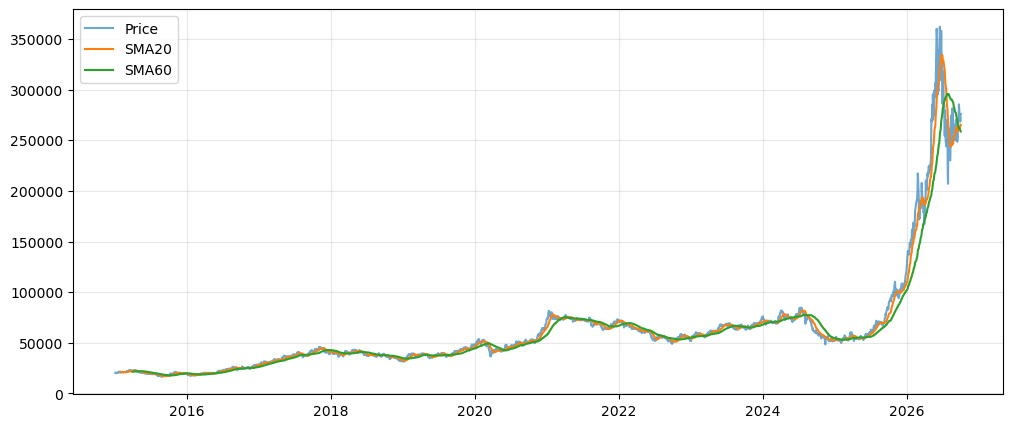

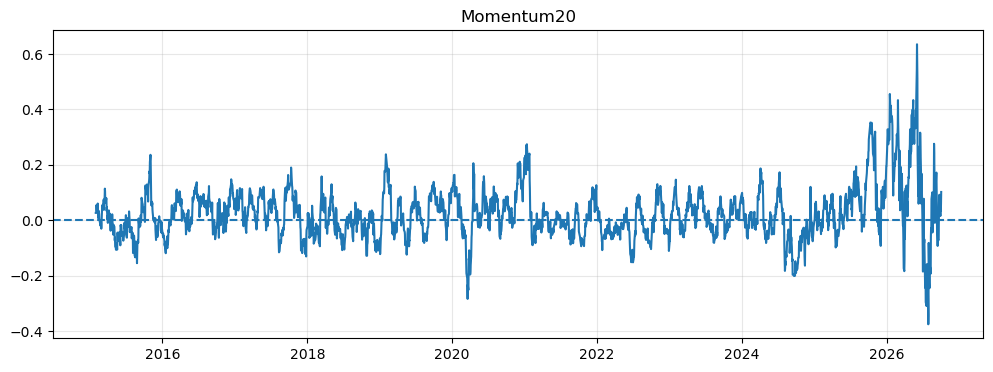

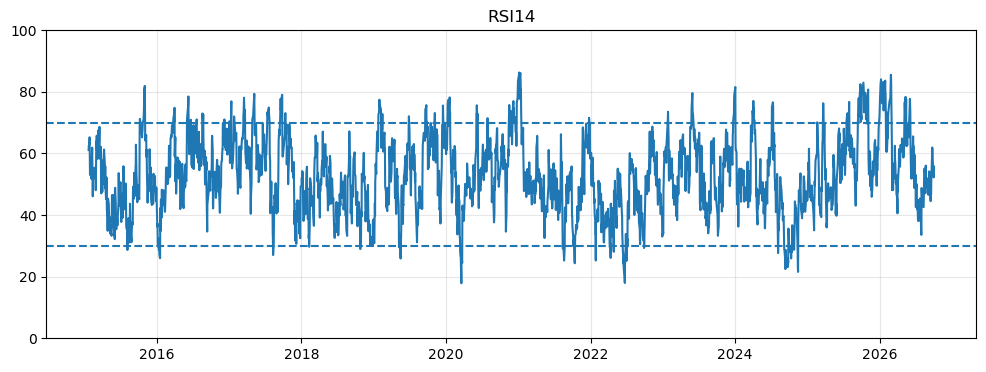

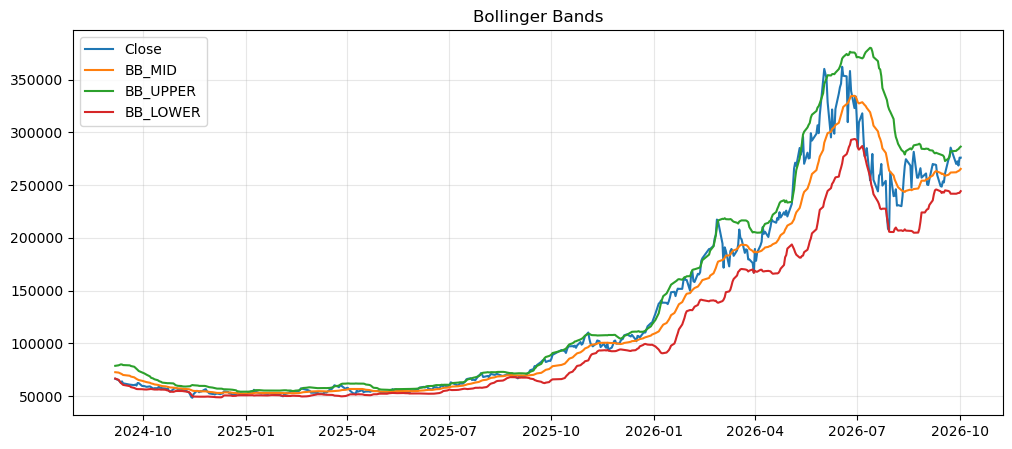

In [5]:
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(df["Date"],df["Close"],label="Price",alpha=.65)
ax.plot(df["Date"],df["SMA20"],label="SMA20"); ax.plot(df["Date"],df["SMA60"],label="SMA60")
ax.legend(); ax.grid(alpha=.3); plt.show()

fig,ax=plt.subplots(figsize=(12,4))
ax.plot(df["Date"],df["MOM20"]); ax.axhline(0,ls="--"); ax.set_title("Momentum20"); ax.grid(alpha=.3); plt.show()

fig,ax=plt.subplots(figsize=(12,4))
ax.plot(df["Date"],df["RSI14"]); ax.axhline(70,ls="--"); ax.axhline(30,ls="--")
ax.set_ylim(0,100); ax.set_title("RSI14"); ax.grid(alpha=.3); plt.show()

x=df.tail(500)
fig,ax=plt.subplots(figsize=(12,5))
for c in ["Close","BB_MID","BB_UPPER","BB_LOWER"]: ax.plot(x["Date"],x[c],label=c)
ax.legend(); ax.set_title("Bollinger Bands"); ax.grid(alpha=.3); plt.show()

# Part 5. Indicator → Signal → Position
Lab의 canonical 전략:
$$
Signal_t=I(SMA20_t>SMA60_t)
$$
오늘 종가까지 계산한 신호는 다음 거래일부터 적용하므로
$$
Position_t=Signal_{t-1}
$$
입니다.

In [6]:
df["SMA_SIGNAL"]=(df["SMA20"]>df["SMA60"]).astype(int)
df["POSITION"]=df["SMA_SIGNAL"].shift(1).fillna(0).astype(int)
df[["Date","SMA_SIGNAL","POSITION"]].tail()

,Date,SMA_SIGNAL,POSITION
2875,2026-09-28,1,0
2876,2026-09-29,1,1
2877,2026-09-30,1,1
2878,2026-10-01,1,1
2879,2026-10-02,1,1


# Part 6. Backtest와 거래비용
모든 핵심 지표가 계산 가능한 공통 시작일부터 비교하며 평가 시작일에는 현금에서 출발합니다.
$$
Turnover_t=|Position_t-Position_{t-1}|
$$
$$
R_t^{net}=Position_tR_t-c\times Turnover_t
$$
Buy-and-Hold에도 최초 진입비용을 한 번 부과합니다.

In [7]:
req=["RET","SMA20","SMA60","MOM20","RSI14","BB_MID","BB_UPPER","BB_LOWER"]
start=df.index[df[req].notna().all(axis=1)][0]
ev=df.loc[start:].copy().reset_index(drop=True)

ev["STRATEGY_RET_GROSS"]=ev["POSITION"]*ev["RET"]
ev["TURNOVER"]=ev["POSITION"].diff().abs(); ev.loc[0,"TURNOVER"]=abs(ev.loc[0,"POSITION"])
ev["STRATEGY_RET_NET"]=ev["STRATEGY_RET_GROSS"]-COST*ev["TURNOVER"]

ev["BH_POSITION"]=1
ev["BH_TURNOVER"]=0.0; ev.loc[0,"BH_TURNOVER"]=1.0
ev["BH_RET_NET"]=ev["RET"]-COST*ev["BH_TURNOVER"]
print("Evaluation start:",ev["Date"].iloc[0].date())

Evaluation start: 2015-03-31


,CAGR,Volatility,Sharpe,MDD,Annual_Turnover,Trades,Exposure
Buy & Hold,0.253855,0.339585,0.834704,-0.428474,0.089330,1.0,1.000000
SMA20/60,0.190935,0.268614,0.784680,-0.448837,4.555831,51.0,0.593761


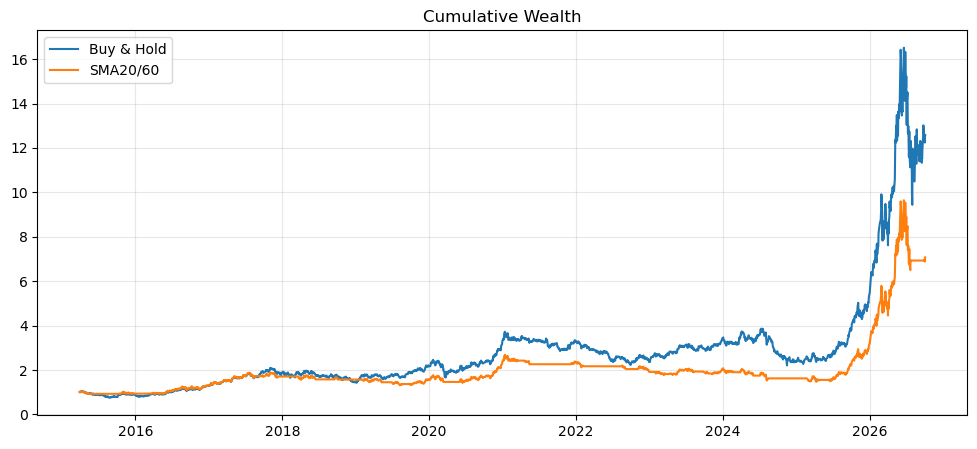

In [8]:
def cagr(r):
    r=r.dropna()
    return (1+r).prod()**(TRADING_DAYS/len(r))-1 if len(r) else np.nan
def vol(r): return r.dropna().std(ddof=1)*np.sqrt(TRADING_DAYS)
def sharpe(r):
    r=r.dropna(); s=r.std(ddof=1)
    return np.sqrt(TRADING_DAYS)*r.mean()/s if s>0 else np.nan
def mdd(r):
    w=(1+r.fillna(0)).cumprod()
    return (w/w.cummax()-1).min()
def stats(r,pos,to):
    years=len(r.dropna())/TRADING_DAYS
    return {"CAGR":cagr(r),"Volatility":vol(r),"Sharpe":sharpe(r),"MDD":mdd(r),
            "Annual_Turnover":to.fillna(0).sum()/years if years else np.nan,
            "Trades":int((to.fillna(0)>0).sum()),"Exposure":pos.fillna(0).mean()}

perf=pd.DataFrame({
    "Buy & Hold":stats(ev["BH_RET_NET"],ev["BH_POSITION"],ev["BH_TURNOVER"]),
    "SMA20/60":stats(ev["STRATEGY_RET_NET"],ev["POSITION"],ev["TURNOVER"])
}).T
display(perf)

ev["WEALTH_BH"]=(1+ev["BH_RET_NET"].fillna(0)).cumprod()
ev["WEALTH_SMA"]=(1+ev["STRATEGY_RET_NET"].fillna(0)).cumprod()
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(ev["Date"],ev["WEALTH_BH"],label="Buy & Hold")
ax.plot(ev["Date"],ev["WEALTH_SMA"],label="SMA20/60")
ax.legend(); ax.grid(alpha=.3); ax.set_title("Cumulative Wealth"); plt.show()

# Part 7. Backtest Diagnostics
1. Always-long 전략은 Buy-and-Hold를 정확히 복제해야 합니다.
2. `shift(1)`을 제거한 잘못된 전략과 비교하여 look-ahead bias를 확인합니다.

In [9]:
p=pd.Series(1,index=ev.index,dtype=int)
to=p.diff().abs(); to.iloc[0]=1.0
r=p*ev["RET"]-COST*to
np.testing.assert_allclose(r.to_numpy(),ev["BH_RET_NET"].to_numpy(),equal_nan=True)
print("PASS: Always-long reproduces Buy & Hold")

ev["WRONG_POSITION"]=ev["SMA_SIGNAL"]
ev["WRONG_TURNOVER"]=ev["WRONG_POSITION"].diff().abs()
ev.loc[0,"WRONG_TURNOVER"]=abs(ev.loc[0,"WRONG_POSITION"])
ev["WRONG_RET_NET"]=ev["WRONG_POSITION"]*ev["RET"]-COST*ev["WRONG_TURNOVER"]
display(pd.DataFrame({
    "Correct_shifted":stats(ev["STRATEGY_RET_NET"],ev["POSITION"],ev["TURNOVER"]),
    "Wrong_no_shift":stats(ev["WRONG_RET_NET"],ev["WRONG_POSITION"],ev["WRONG_TURNOVER"])
}).T)

PASS: Always-long reproduces Buy & Hold


,CAGR,Volatility,Sharpe,MDD,Annual_Turnover,Trades,Exposure
Correct_shifted,0.190935,0.268614,0.784680,-0.448837,4.555831,51.0,0.593761
Wrong_no_shift,0.211550,0.268889,0.848026,-0.365010,4.555831,51.0,0.594116


# Part 8. Train / Test
평가기간을 시간 순서대로 70% Train, 30% Test로 나눕니다.
$$
\boxed{\text{Design on Train}\rightarrow\text{Freeze Rule}\rightarrow\text{Evaluate Once on Test}}
$$
지표는 전체 시계열에서 계산한 뒤 구간을 자릅니다.

In [10]:
split=int(len(ev)*0.70)
train=ev.iloc[:split].copy().reset_index(drop=True)
test=ev.iloc[split:].copy().reset_index(drop=True)
print("Train:",train["Date"].min().date(),"to",train["Date"].max().date())
print("Test :",test["Date"].min().date(),"to",test["Date"].max().date())
display(pd.DataFrame({
    "Train":stats(train["STRATEGY_RET_NET"],train["POSITION"],train["TURNOVER"]),
    "Test":stats(test["STRATEGY_RET_NET"],test["POSITION"],test["TURNOVER"])
}).T)

Train: 2015-03-31 to 2023-04-07
Test : 2023-04-10 to 2026-10-02


,CAGR,Volatility,Sharpe,MDD,Annual_Turnover,Trades,Exposure
Train,0.079050,0.192953,0.490780,-0.336474,4.340426,34.0,0.563323
Test,0.498803,0.391494,1.229407,-0.326154,5.057851,17.0,0.664699


# Part 9. Circular-Shift Benchmark
iid random signal은 exposure는 맞춰도 turnover가 달라질 수 있습니다. 따라서 Position 시계열을 원형 이동하여 **포지션 구조는 유지하고 시장과의 timing만 변경**합니다. Test 구간에서 500회 비교합니다.

Actual Test Sharpe: 1.229
Circular-shift percentile: 82.8%


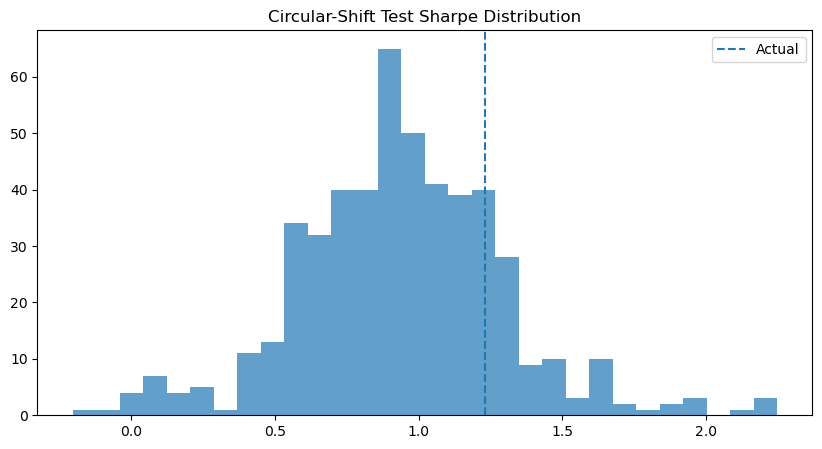

In [11]:
def circular_shift_benchmark(position,ret,n_sim=500,cost=COST,seed=42):
    pos=position.fillna(0).astype(int).reset_index(drop=True)
    rr=ret.fillna(0).reset_index(drop=True)
    T=len(pos)
    if T<50: raise ValueError("Test sample too short")
    rng=np.random.default_rng(seed)
    shifts=rng.integers(20,T-20,size=n_sim)
    out=[]
    for k in shifts:
        p=pd.Series(np.roll(pos.to_numpy(),k))
        to=p.diff().abs(); to.iloc[0]=abs(p.iloc[0])
        out.append(sharpe(p*rr-cost*to))
    return np.asarray(out)

random_sharpes=circular_shift_benchmark(test["POSITION"],test["RET"])
actual_sharpe=sharpe(test["STRATEGY_RET_NET"])
valid=random_sharpes[np.isfinite(random_sharpes)]
pct=100*np.mean(valid<=actual_sharpe)
print("Actual Test Sharpe:",round(actual_sharpe,3))
print("Circular-shift percentile:",f"{pct:.1f}%")
fig,ax=plt.subplots(figsize=(10,5))
ax.hist(valid,bins=30,alpha=.7); ax.axvline(actual_sharpe,ls="--",label="Actual")
ax.legend(); ax.set_title("Circular-Shift Test Sharpe Distribution"); plt.show()

# Part 10. WEEK 03 ASSIGNMENT

## A1. Indicator Verification
SMA, Momentum, RSI, Bollinger Bands 각각이 가격의 어떤 정보를 변환하는지 설명하고 자신의 실제 결과 또는 그래프를 인용하십시오.


## A1 답안

기준 시점은 마지막 관측일인 2026-10-02이며(Part 4 표), 그래프는 Part 4 출력이다.

### SMA (20일, 60일)
- **변환하는 정보:** 최근 n일 가격의 평균이다. 일별 잡음을 걸러내 추세의 방향과 수준을 보여준다. n이 클수록 곡선이 매끄럽지만 가격 변화에 늦게 반응한다(lag).
- **내 결과:** 종가 276,000원, SMA20 265,325원, SMA60 258,717원이다. 종가 > SMA20 > SMA60이므로 단기·중기 모두 상승 배열이다. Part 5 표를 보면 SMA_SIGNAL은 2026-09-28에 1이 되었다(같은 날 POSITION은 아직 0). 즉 이날 SMA20이 SMA60 위로 다시 올라섰다.
- **그래프:** 2025년 하반기부터 2026년 중반까지 급등 구간에서 SMA20이 SMA60 위에 머물렀다. 2026년 여름 고점(약 36만 원) 이후 급락하자 SMA20이 먼저 꺾여 SMA60 아래로 내려갔다. SMA60이 SMA20보다 늦게 꺾이는 모습에서 긴 이동평균의 지연을 확인할 수 있다.

### Momentum (20일)
- **변환하는 정보:** 20거래일 전 대비 수익률이다. 가격 수준이 아니라 최근 약 한 달간 가격 변화의 방향과 속도를 나타낸다.
- **내 결과:** MOM20 = 10.2%로, 20거래일 전보다 약 10% 올랐다.
- **그래프:** 대부분의 기간에 0을 중심으로 ±20% 안에서 오르내린다. 2020년 초에는 약 -28%(코로나 급락)까지 내려갔다. 2026년에는 최고 약 +63%, 최저 약 -37%로 변동 폭이 과거보다 훨씬 커졌다.

### RSI (14일, Wilder 방식)
- **변환하는 정보:** 최근 상승폭 평균과 하락폭 평균의 상대적 크기를 0~100으로 표준화한 값이다. 가격 수준과 무관하게 상승 압력과 하락 압력 중 어느 쪽이 우세한지 보여주며, 관례적으로 70 이상은 과열, 30 이하는 과매도로 본다.
- **내 결과:** RSI14 = 55.7로, 30~70 사이의 중립 구간이다.
- **그래프:** 2021년 초와 2025년 말~2026년 초에 80을 넘는 과열 구간이 있었다. 2020년 초와 2022년 중반에는 20 근처까지 떨어졌다. 2025년 말~2026년 초처럼 강한 상승장에서는 RSI가 70 위에 여러 차례, 오래 머물 수 있다.

### Bollinger Bands (20일, ±2σ, ddof=0)
- **변환하는 정보:** SMA20을 중심선으로 하고 20일 표준편차의 2배를 위아래로 더한 밴드다. 가격이 최근 평균 대비 어디에 있는지(상대적 위치)와 최근 변동성의 크기(밴드 폭)를 함께 보여준다.
- **내 결과:** 하단 244,222원, 중심 265,325원, 상단 286,428원이다. 밴드 폭은 약 42,206원으로 중심선의 약 15.9%다. 종가 276,000원은 하단에서 상단까지의 약 75% 위치(%B ≈ 0.75)로, 중심선 위·상단 아래에 있다.
- **그래프(최근 500거래일):** 2025년 초 가격이 5만 원대에서 횡보할 때는 밴드가 매우 좁았다. 2026년 급등·급락 구간에서는 밴드가 크게 넓어졌다. 2026년 8월 무렵에는 종가가 하단 밴드 근처까지 급락했다.

### 정리
SMA와 Momentum은 가격의 **추세(방향)**를, RSI와 Bollinger Bands는 최근 범위 안에서의 **상대적 위치(과열·과매도)와 변동성**을 나타낸다. 내 전략은 SMA로 추세를 판단하고 RSI로 과열 여부를 걸러낸다.


## A2. Strategy Specification — Test를 보기 전에 작성
다음 지표 중 **최소 2개**를 사용하십시오: SMA, Momentum, RSI, Bollinger Bands.

반드시 기록할 것:
- 사용 지표와 parameter
- Long 조건
- Flat 조건
- 경제적·투자적 논리
- 최종 규칙 선택 전 Train에서 시도한 전략/parameter 조합의 수

많은 규칙을 시도한 뒤 가장 좋은 것만 선택하면 Train에서도 data snooping이 발생할 수 있습니다.

## A2 답안

### 사용 지표와 parameter
- **SMA:** 20일, 60일 단순이동평균
- **RSI:** 14일, Wilder 방식, 과열 기준 70

### Long 조건
$$
Signal_t = I\left(SMA20_t > SMA60_t \;\text{and}\; RSI14_t < 70\right)
$$
두 조건을 모두 만족하면 Signal = 1이고, `shift(1)`로 다음 거래일부터 보유한다(Position_t = Signal_{t-1}).

### Flat 조건
다음 중 하나라도 해당하면 Signal = 0(현금 보유)이다.
- SMA20 ≤ SMA60: 하락 또는 횡보 추세
- RSI14 ≥ 70: 상승 추세이더라도 단기 과열
- 지표가 아직 계산되지 않은 초기 구간(NaN과의 비교는 False)

### 경제적·투자적 논리
- **추세 추종:** 새로운 정보가 가격에 천천히 반영되거나 투자자들이 추세를 따라 매매하면 가격 추세가 일정 기간 지속될 수 있다. 단기 평균(SMA20)이 중기 평균(SMA60) 위에 있으면 상승 추세로 보고 보유한다.
- **과열 회피:** 짧은 기간 급등해 RSI가 70 이상이면 단기 되돌림 위험이 커질 수 있다. 이런 고점 부근에서는 신규 진입과 보유를 피한다.
- **예상되는 대가:** 급등 후 조정 구간의 손실은 줄일 수 있지만, 강한 상승장에서 RSI가 70 위에 오래 머물면 상승분 일부를 놓친다. 또 SMA 조건만 쓸 때보다 Exposure는 줄고 매매 횟수(거래비용)는 늘어날 것으로 예상된다.

### Train에서 시도한 전략/parameter 조합 수
총 **4개**(최종 규칙 1개 + 이웃 설정 3개)를 Train 구간에서만 비교했다.

| # | 규칙 | 비고 |
|---|---|---|
| 1 | SMA20 > SMA60 and RSI14 < 70 | 최종 선택 |
| 2 | SMA10 > SMA50 and RSI14 < 70 | 이동평균 기간 변경 |
| 3 | SMA20 > SMA60 and RSI14 < 80 | RSI 과열 기준 완화 |
| 4 | SMA20 > SMA60 | RSI 필터 없음(Lab 기본 전략) |

4개 규칙을 **Train 구간(2015-03-31 ~ 2023-04-07)에서만** 같은 방식(shift(1), 거래비용 0.15%)으로 비교했다(바로 아래 코드 셀). 비교 기준은 **Train Net Sharpe**이다.

| # | 규칙 | Train Net Sharpe | Train CAGR | Train MDD | Trades | Exposure |
|---|---|---|---|---|---|---|
| 1 | SMA20 > SMA60 and RSI14 < 70 (최종) | 0.460 | 6.9% | -32.4% | 92 | 50.4% |
| 2 | SMA10 > SMA50 and RSI14 < 70 | 0.407 | 5.9% | -30.0% | 125 | 48.7% |
| 3 | SMA20 > SMA60 and RSI14 < 80 | 0.470 | 7.4% | -32.5% | 40 | 55.8% |
| 4 | SMA20 > SMA60 | 0.491 | 7.9% | -33.6% | 34 | 56.3% |

- 최종 규칙(1번)은 Train Sharpe 기준으로 4개 중 **3위**이다. 즉 Train에서 가장 좋은 규칙을 골라서 정한 것이 **아니다**. 규칙은 경제적 논리(추세 추종 + 과열 회피)로 먼저 정했고, 이웃 설정은 비교용으로 돌렸다. 비교 결과를 보고도 규칙을 바꾸지 않았다.
- 네 규칙의 Train Sharpe 차이(0.41~0.49)는 크지 않아, Train만으로는 어느 규칙이 우월하다고 말하기 어렵다.
- RSI 필터를 넣거나 기준을 낮출수록 Trades가 늘고(34 → 40 → 92회) Train Sharpe는 오히려 낮아졌다. 과열 회피 필터가 Train에서도 도움이 되지 않았다.
- 최종 규칙은 Train 비교에서도, A3 이후 Test 결과를 본 뒤에도 변경하지 않았다.
- 최종 규칙을 "4개 중 가장 좋은 것"으로 고르지는 않았으므로 best-of-4 선택 편향은 없다. 다만 Train에서 4개 조합을 시도했다는 사실은 multiple testing 관점에서 기록한다(A5-7 참고).


In [12]:
# A2: Train 구간에서만 4개 규칙 비교 (Test는 사용하지 않음)
cands = {
    "1 SMA20/60 & RSI<70 (최종)": (df["SMA20"] > df["SMA60"]) & (df["RSI14"] < 70),
    "2 SMA10/50 & RSI<70":        (sma(df["Close"],10) > sma(df["Close"],50)) & (df["RSI14"] < 70),
    "3 SMA20/60 & RSI<80":        (df["SMA20"] > df["SMA60"]) & (df["RSI14"] < 80),
    "4 SMA20/60 only":            (df["SMA20"] > df["SMA60"]),
}
rows = {}
for name, sig in cands.items():
    pos = sig.astype(int).shift(1).fillna(0).astype(int)
    e = pd.DataFrame({"RET": df["RET"], "POS": pos}).loc[start:].reset_index(drop=True)
    tr = e.iloc[:int(len(e)*0.70)].copy().reset_index(drop=True)   # Train만 사용
    to = tr["POS"].diff().abs(); to.iloc[0] = abs(tr["POS"].iloc[0])
    net = tr["POS"]*tr["RET"] - COST*to
    rows[name] = stats(net, tr["POS"], to)
display(pd.DataFrame(rows).T[["Sharpe","CAGR","MDD","Trades","Exposure"]])


,Sharpe,CAGR,MDD,Trades,Exposure
1 SMA20/60 & RSI<70 (최종),0.459573,0.069436,-0.324103,92.0,0.503546
2 SMA10/50 & RSI<70,0.407383,0.058735,-0.300312,125.0,0.487335
3 SMA20/60 & RSI<80,0.470151,0.074384,-0.324599,40.0,0.557751
4 SMA20/60 only,0.490780,0.079050,-0.336474,34.0,0.563323


In [ ]:
def my_strategy(data: pd.DataFrame) -> pd.Series:
    # 과열 회피형 추세추종: SMA20/60 추세 + RSI14 < 70 필터 (AND)
    # NaN과의 비교는 False이므로 지표가 계산되지 않는 초기 구간은 자동으로 Flat(0)
    c1 = data["SMA20"] > data["SMA60"]   # 상승 추세
    c2 = data["RSI14"] < 70              # 과열되지 않음
    return (c1 & c2).astype(int)ㄴ

## A3. Strategy Freeze & Out-of-Sample Backtest
`my_strategy()`를 완성한 뒤 아래 셀을 실행합니다. 이 시점부터 전략 규칙을 고정하고 Test 결과를 본 뒤 규칙을 변경하지 마십시오.

In [14]:
my_signal=my_strategy(df)
assert isinstance(my_signal,pd.Series) and my_signal.index.equals(df.index)
assert set(my_signal.dropna().unique()).issubset({0,1})

student=df.copy()
student["MY_SIGNAL"]=my_signal
student["MY_POSITION"]=student["MY_SIGNAL"].shift(1).fillna(0).astype(int)
student_ev=student.loc[start:].copy().reset_index(drop=True)
student_ev["MY_TURNOVER"]=student_ev["MY_POSITION"].diff().abs()
student_ev.loc[0,"MY_TURNOVER"]=abs(student_ev.loc[0,"MY_POSITION"])
student_ev["MY_RET_GROSS"]=student_ev["MY_POSITION"]*student_ev["RET"]
student_ev["MY_RET_NET"]=student_ev["MY_RET_GROSS"]-COST*student_ev["MY_TURNOVER"]

ss=int(len(student_ev)*.70)
student_train=student_ev.iloc[:ss].copy().reset_index(drop=True)
student_test=student_ev.iloc[ss:].copy().reset_index(drop=True)
student_test["BH_POSITION"]=1
student_test["BH_TURNOVER"]=0.0; student_test.loc[0,"BH_TURNOVER"]=1.0
student_test["BH_RET_NET"]=student_test["RET"]-COST*student_test["BH_TURNOVER"]

student_perf=pd.DataFrame({
    "Buy & Hold":stats(student_test["BH_RET_NET"],student_test["BH_POSITION"],student_test["BH_TURNOVER"]),
    "My Strategy":stats(student_test["MY_RET_NET"],student_test["MY_POSITION"],student_test["MY_TURNOVER"])
}).T
display(student_perf)

,CAGR,Volatility,Sharpe,MDD,Annual_Turnover,Trades,Exposure
Buy & Hold,0.564970,0.475485,1.177202,-0.428474,0.297521,1.0,1.000000
My Strategy,0.245961,0.352234,0.799605,-0.328761,13.983471,47.0,0.539551


## A4. 거래비용, Look-Ahead Bias, Random Benchmark
1. Gross와 Net 성과를 비교하십시오.
2. `shift(1)`을 제거한 잘못된 결과와 비교하십시오.
3. 자신의 Test Position을 circular shift한 500개 benchmark와 비교하십시오.
4. 모든 해석에서 자신의 실제 숫자를 인용하십시오.

,CAGR,Volatility,Sharpe,MDD,Annual_Turnover,Trades,Exposure
Gross,0.272446,0.352053,0.859595,-0.326154,13.983471,47.0,0.539551
Net,0.245961,0.352234,0.799605,-0.328761,13.983471,47.0,0.539551


,CAGR,Volatility,Sharpe,MDD,Annual_Turnover,Trades,Exposure
Correct_shifted,0.245961,0.352234,0.799605,-0.328761,13.983471,47.0,0.539551
Wrong_no_shift,-0.160130,0.345538,-0.330992,-0.503944,13.983471,47.0,0.539551


My Test Sharpe: 0.8
My circular-shift percentile: 51.0%


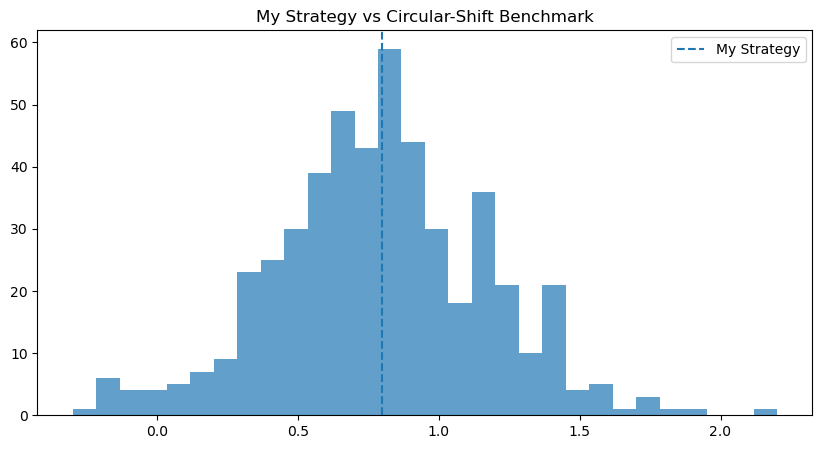

In [15]:
gross_net=pd.DataFrame({
    "Gross":stats(student_test["MY_RET_GROSS"],student_test["MY_POSITION"],student_test["MY_TURNOVER"]),
    "Net":stats(student_test["MY_RET_NET"],student_test["MY_POSITION"],student_test["MY_TURNOVER"])
}).T
display(gross_net)

student_test["WRONG_POSITION"]=student_test["MY_SIGNAL"].fillna(0).astype(int)
student_test["WRONG_TURNOVER"]=student_test["WRONG_POSITION"].diff().abs()
student_test.loc[0,"WRONG_TURNOVER"]=abs(student_test.loc[0,"WRONG_POSITION"])
student_test["WRONG_RET_NET"]=student_test["WRONG_POSITION"]*student_test["RET"]-COST*student_test["WRONG_TURNOVER"]
display(pd.DataFrame({
    "Correct_shifted":stats(student_test["MY_RET_NET"],student_test["MY_POSITION"],student_test["MY_TURNOVER"]),
    "Wrong_no_shift":stats(student_test["WRONG_RET_NET"],student_test["WRONG_POSITION"],student_test["WRONG_TURNOVER"])
}).T)

my_random=circular_shift_benchmark(student_test["MY_POSITION"],student_test["RET"],seed=123)
my_actual=sharpe(student_test["MY_RET_NET"])
my_valid=my_random[np.isfinite(my_random)]
my_pct=100*np.mean(my_valid<=my_actual)
print("My Test Sharpe:",round(my_actual,3))
print("My circular-shift percentile:",f"{my_pct:.1f}%")
fig,ax=plt.subplots(figsize=(10,5))
ax.hist(my_valid,bins=30,alpha=.7); ax.axvline(my_actual,ls="--",label="My Strategy")
ax.legend(); ax.set_title("My Strategy vs Circular-Shift Benchmark"); plt.show()

## A5. 결과 해석
다음 질문에 **자신의 실제 결과 숫자를 인용하여** 답하십시오.

1. My Strategy와 Buy-and-Hold의 Test CAGR, Sharpe, MDD, Exposure를 비교하십시오.
2. 거래비용 전후 성과가 얼마나 달라졌습니까? Turnover와 연결하여 설명하십시오.
3. Exposure 차이가 위험지표 해석에 어떤 영향을 줍니까?
4. `shift(1)` 제거 시 결과가 어떻게 변했으며 왜 잘못된 백테스트입니까?
5. 실제 Test Sharpe는 circular-shift distribution의 몇 percentile입니까?
6. 이 결과만으로 미래 예측력이 있다고 결론 내릴 수 있습니까?
7. Train에서 몇 개의 규칙/parameter 조합을 시도했으며 이것이 multiple testing과 어떤 관련이 있습니까?

## A5 답안

Test 구간: 2023-04-10 ~ 2026-10-02 (약 3.4년)

### 핵심 숫자 요약

| 지표 | Buy & Hold | My Strategy |
|---|---|---|
| CAGR | 56.5% | 24.6% |
| Volatility | 47.5% | 35.2% |
| Sharpe | 1.18 | 0.80 |
| MDD | -42.8% | -32.9% |
| Annual Turnover | 0.30 | 13.98 |
| Trades | 1 | 47 |
| Exposure | 100% | 54.0% |

| A4 진단 | 값 |
|---|---|
| Gross CAGR → Net CAGR | 27.2% → 24.6% (-2.6%p) |
| Gross Sharpe → Net Sharpe | 0.86 → 0.80 |
| 올바른 Sharpe / shift 제거 Sharpe | 0.80 / -0.33 |
| 올바른 CAGR / shift 제거 CAGR | 24.6% / -16.0% |
| Circular-shift percentile | 51.0% |

### 1. B&H와의 비교
- 내 전략의 CAGR(24.6%)은 B&H(56.5%)의 절반에도 못 미쳤고, Sharpe도 0.80 대 1.18로 낮았다.
- MDD만 -32.9% 대 -42.8%로 약 10%p 얕았다.
- Test 기간은 연평균 약 56%씩 오른 강한 상승장이라, 주식을 들고 있지 않은 날(Exposure 54.0%)이 많을수록 불리했다.

### 2. 거래비용 전후
- CAGR이 27.2%에서 24.6%로 2.6%p 줄었고, Sharpe는 0.86에서 0.80으로 낮아졌다.
- 연간 비용 부담은 Annual Turnover 13.98 × 0.15% ≈ 2.1%다.
- 이 비용은 연 27.2%로 불어나는 자산에 비례해 깎이므로, CAGR 기준 감소폭은 약 1.272 × 2.1% ≈ 2.7%p가 된다. 실제 감소폭 2.6%p와 거의 같다.
- Test 약 3.4년 동안 47번(연 약 14번) 포지션을 바꿨다. 매매가 잦을수록 비용 부담이 커진다.

### 3. Exposure와 위험지표
- 변동성(35.2%)과 MDD가 낮은 것은 54%만 투자한 현금 비중 때문이다.
- 변동성은 B&H 변동성에 투자 비중의 제곱근을 곱한 값(47.5% × √0.54 ≈ 34.9%)과 거의 같아, 전략이 위험을 잘 피했다고 보기 어렵다.
- 위험 대비 수익으로 비교하면 Sharpe 0.80으로, 아무 날이나 54% 투자했을 때의 기대치(1.18 × √0.54 ≈ 0.87)보다도 약간 낮다.

### 4. shift(1) 제거
- shift를 빼면 Sharpe가 0.80에서 -0.33으로, CAGR이 24.6%에서 -16.0%로 바뀐다.
- 그날 종가로 만든 신호로 그날 수익을 얻는 것은 실제로 불가능하므로 잘못된 백테스트다.
- 이번에는 결과가 오히려 나빠졌다. RSI가 70을 넘는 날은 대개 크게 오른 날이라 상승일을 놓치고, 70 아래로 내려오는 날은 대개 떨어진 날이라 하락일에 보유하게 된다.
- look-ahead bias는 결과를 항상 좋게 만드는 것이 아니라 현실과 다르게 왜곡한다.

### 5. Circular-shift percentile
- 실제 Test Sharpe 0.80은 500개 분포의 51.0 percentile로, 분포의 중앙값 수준이다.
- 95 percentile 기준에 한참 못 미치므로 내 타이밍은 우연과 구분되지 않는다.

### 6. 예측력 결론
예측력이 있다고 결론 내릴 수 없다.
- 한 종목(삼성전자)의 한 구간(약 3.4년)뿐인 결과다.
- percentile이 51.0%로 무작위 타이밍 수준이다.
- 비용 전 Sharpe(0.86)도 이미 무작위 54% 투자 수준(약 0.87)이었다.
- 상승장의 영향이 커서 전략의 실력과 시장 국면을 구분하기 어렵다.

### 7. Multiple testing
- Train에서 규칙/parameter 조합 4개를 시도했다(최종 규칙 1개 + 이웃 설정 3개). 최종 규칙의 Train Net Sharpe는 0.460으로 4개 중 3위였고(1위는 RSI 필터 없는 SMA20/60의 0.491), 가장 좋은 것을 골라 확정한 것은 아니다.
- 그래도 여러 개를 시도해 가장 좋은 것을 고르면 우연히 좋아 보이는 규칙이 뽑힐 확률이 커진다. 이번에는 best-of-4 선택이 아니어서 이 편향은 작지만, 시도한 조합 수는 투명하게 기록해야 한다.
- 각 규칙이 우연히 5% 기준을 통과할 확률이 5%라도, m개 중 하나 이상 통과할 확률은 1-(1-0.05)^m이고 m=4이면 약 18.5%다.
- 시도 수가 많을수록 이 확률은 커지며, 이것이 data snooping과 overfitting 문제다.

### 추가 관찰: Lab 기본 전략(SMA20/60)과의 비교
*Test 결과를 본 뒤의 사후 비교이며, 규칙 변경에는 사용하지 않았다.*

| 지표 (Test) | SMA20/60 (Lab, Part 8·9) | My Strategy |
|---|---|---|
| CAGR | 49.9% | 24.6% |
| Sharpe | 1.23 | 0.80 |
| MDD | -32.6% | -32.9% |
| Exposure | 66.5% | 54.0% |
| Trades | 17 | 47 |
| Annual Turnover | 5.06 | 13.98 |
| Circular-shift percentile | 82.8% | 51.0% |

- RSI 필터를 더하자 Exposure는 66.5%에서 54.0%로 줄고 Trades는 17회에서 47회로 늘었으며, Sharpe는 1.23에서 0.80으로 낮아졌다.
- MDD는 -32.6%와 -32.9%로 거의 같다. 과열 구간을 피해 손실을 줄이려던 의도가 이번 Test에서는 나타나지 않았다.
- A1의 RSI 그래프처럼 강한 상승장에서 RSI가 70 위에 자주 머물러, 상승 구간 일부를 놓친 것으로 보인다.
- 다만 이 비교를 근거로 규칙을 바꾸면 Test가 더 이상 out-of-sample이 아니게 된다. 또한 기본 전략의 82.8 percentile도 95 기준에는 미치지 못하므로, 기본 전략 역시 예측력의 증거로 보기는 어렵다(두 benchmark는 seed가 달라 percentile 비교는 참고용이다).


# Week 03 핵심 메시지

이번 주의 첫 번째 핵심 메시지는 다음과 같습니다.

$$
\boxed{
\text{Price}
\rightarrow
\text{Indicator}
\rightarrow
\text{Signal}
\rightarrow
\text{Position}
\rightarrow
\text{Return}
}
$$

그리고 더 중요한 두 번째 메시지는 다음과 같습니다.

$$
\boxed{
\text{Backtest Performance}
\neq
\text{Evidence of Predictability}
}
$$

다음 주에는 다음 문제를 더 체계적으로 다룹니다.

- parameter tuning
- data snooping
- overfitting
- multiple testing
- transaction costs
- out-of-sample evaluation

## 제출 전 Checklist

- [ ] Notebook을 처음부터 끝까지 실행했다.
- [x] 4개 핵심 기술적 지표를 확인했다.
- [x] `my_strategy()`에 최소 2개 지표를 사용했다.
- [x] 전략의 경제적·투자적 논리를 설명했다.
- [x] Train에서 시도한 전략 또는 parameter 조합 수를 기록했다.
- [x] `shift(1)`을 적용했다.
- [x] 거래비용을 적용했다.
- [x] Test에서 Buy-and-Hold와 비교했다.
- [x] CAGR, Volatility, Sharpe, MDD를 확인했다.
- [x] Turnover, Trades, Exposure를 확인했다.
- [x] Look-ahead bias를 확인했다.
- [x] Circular-shift benchmark를 수행했다.
- [x] 해석에서 자신의 실제 결과 숫자를 인용했다.
